# 15 - Protocol Attribution Across the Feature Pipeline

## Why this notebook exists

R2C3 objects that the CNN comparison changes two things at once - the protocol
*and* the implementation - so the gap cannot be attributed. Notebook 13 fixes that
for the CNN. But the same criticism applies with equal force to the feature
pipeline: every accuracy in the manuscript is measured under one partition, so a
reader has no way to know whether 90.71% on Tomasov reflects the method or the
split.

This notebook answers that for **every configuration the paper reports**, using
the design that makes attribution possible: *one population, one model, one seed,
two partitions*.

| Arm | Partition | Rows |
|---|---|---|
| **A** | our leakage-safe split (Tomasov: blocked segments + guard band; Cao: session-grouped) | the final manifest |
| **B** | stratified **random** split, the protocol both source papers used | **identical rows to A** |

Nothing else varies. The A-to-B difference is therefore a pure measurement of how
much each configuration's reported performance depends on the evaluation protocol.

## Configurations covered

1. `full_1002` - the fused multi-domain feature set
2. `8_consensus` - features chosen by all eight selectors
3. Each of the eight selectors on its own, at a common top-K
4. Dimensionality reduction: PCA at 95% retained variance, and LDA
5. The two published CNN baselines, read from notebooks 10 and 13

## The rule that makes this honest

**Feature selection and dimensionality reduction are refitted inside every arm**,
on that arm's training rows only. Reusing the stored selection would leak arm A's
partition into arm B and would understate the effect. Refitting is also the more
interesting measurement: it asks how much each *selector* is fooled by leakage,
not just how much the classifier is.

## Reading the outcome

A large A-to-B gap means the configuration is protocol-sensitive and any
literature number reported for it under a random split is inflated. A small gap
means the configuration is robust and its published numbers can be taken at face
value. Both outcomes are publishable; what is not defensible is not knowing.

## One comparison to read carefully

The eight `top100_*` configurations hold dimensionality fixed at 100 features in both
arms, so their A-to-B gap is a clean protocol measurement. `8_consensus` does **not**:
the selector is refitted inside each arm, so the two arms can end up with different
numbers of features, and part of any gap would then be dimensionality rather than
protocol. Read that row against `config_sizes.csv`, and if the two counts differ
materially, quote the fixed-dimensionality rows instead.

In [1]:
import sys, json, time
from pathlib import Path
# No machine-specific path: the kernel starts in Experiment/ (or the repo root).
EXPERIMENT_DIR = Path.cwd() if (Path.cwd() / "dasfe").is_dir() else Path.cwd() / "Experiment"
if str(EXPERIMENT_DIR) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from dasfe import config as C, fusion as F, evaluate as EV, selection as FS

sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIGURE ME -----------------------------
# Tiny end-to-end run - every selector, every configuration, both arms, both
# dimensionality reducers - in minutes.  Writes to a separate `_smoke` directory.
SMOKE = False

DATASETS  = ("tomasov", "cao")
MODEL     = "LightGBM"
STRATEGY  = "class_weight"      # fixed everywhere so only features and split vary
TOP_K     = 100                 # per-selector budget, common to all eight
FS_FAST   = True                # reduced subsample budgets; same eight methods
PCA_VAR   = 0.95
# Cap used only for the selection ensemble refits, which run 2x per dataset.
FS_PER_CLASS = 12000
# Cap for the classifier fits. None uses every row.
# Budget: 11 configurations x 2 arms x 2 datasets = 44 fits, plus 8 for the
# dimensionality-reduction arms. On the Jetson a 1002-feature LightGBM fit over
# the full Tomasov training split runs about 500 s, so expect roughly 3-4 hours
# end to end. Set this to 20000 to halve that.
CLF_PER_CLASS = None
# ------------------------------------------------------------------------

if SMOKE:
    FS_PER_CLASS = 400
    CLF_PER_CLASS = 400
    TOP_K = 25
    print("SMOKE MODE: 400 rows per class, top-25 selectors, separate output.")
    print("Nothing here is a result. Set SMOKE = False for the real run.")

out_dir = C.results_dir("shared", "15_protocol_attribution" + ("_smoke" if SMOKE else ""))
print("output:", out_dir)


def stratified_random_split(df, seed, fractions=C.SPLIT_FRACTIONS):
    # Window-level random assignment - the protocol both source papers used.
    # Stratified by class so the class balance matches arm A exactly and cannot
    # confound the contrast.
    out = np.empty(len(df), dtype=object)
    r = np.random.default_rng(seed)
    for lab, idx in df.groupby("label").indices.items():
        idx = np.asarray(idx).copy()
        r.shuffle(idx)
        n = len(idx)
        n_tr = int(round(fractions[0] * n))
        n_va = int(round(fractions[1] * n))
        out[idx[:n_tr]] = "train"
        out[idx[n_tr:n_tr + n_va]] = "val"
        out[idx[n_tr + n_va:]] = "test"
    return np.asarray(out, dtype=object)


DATA = {}
for ds in DATASETS:
    d = F.load(C.results_dir(ds, "04_fusion"))
    d["manifest"] = d["manifest"].reset_index(drop=True)
    d["split_A"] = d["manifest"]["split"].to_numpy().astype(object)
    d["split_B"] = stratified_random_split(d["manifest"], C.SEED + 303)
    DATA[ds] = d
    a = pd.Series(d["split_A"]).value_counts()
    b = pd.Series(d["split_B"]).value_counts()
    print(f"{ds:9s} X {d['X'].shape}  "
          f"A train/val/test {a.get('train',0):,}/{a.get('val',0):,}/{a.get('test',0):,}  "
          f"B {b.get('train',0):,}/{b.get('val',0):,}/{b.get('test',0):,}")
    assert len(d["split_A"]) == len(d["split_B"]) == len(d["X"])

output: C:\Users\irvin\Desktop\THESIS-MASTERS-UTP\Rerun\Results\shared\15_protocol_attribution


tomasov   X (172458, 1002)  A train/val/test 148,229/12,895/11,334  B 137,966/17,246/17,246
cao       X (15418, 1002)  A train/val/test 12,155/1,460/1,803  B 12,334/1,541/1,543


## 1. Refit the selection ensemble inside each arm

Eight selectors, fitted on the training rows of arm A and again on the training
rows of arm B. Reduced subsample budgets (`FS_FAST`) keep two full ensemble refits
per dataset tractable; the methods themselves are unchanged.

This step is the expensive one. Everything after it is classifier fits.

In [2]:
def subsample(y, per_class, seed=C.SEED):
    if per_class is None:
        return np.arange(len(y))
    rng = np.random.default_rng(seed)
    keep = []
    for lab in np.unique(y):
        idx = np.flatnonzero(y == lab)
        if len(idx) > per_class:
            idx = rng.choice(idx, per_class, replace=False)
        keep.append(idx)
    return np.sort(np.concatenate(keep))


SEL = {}
for ds in DATASETS:
    d = DATA[ds]
    for arm in ("A", "B"):
        sp = d[f"split_{arm}"]
        tr = np.flatnonzero(sp == "train")
        sub = tr[subsample(d["y"][tr], FS_PER_CLASS, C.SEED)]
        print(f"=== {ds} arm {arm}: selection ensemble on {len(sub):,} training rows ===")
        t0 = time.perf_counter()
        res = FS.fit_all(d["X"][sub], d["y"][sub], d["feature_names"],
                         fast=FS_FAST, seed=C.SEED, verbose=True)
        SEL[(ds, arm)] = res
        print(f"  {res['n_methods']} methods in {time.perf_counter()-t0:.0f}s, "
              f"consensus {int(FS.consensus_mask(res).sum())} features")

=== tomasov arm A: selection ensemble on 98,034 training rows ===


  [variance] scored 966 eligible features in 0.1s


  [pearson] scored 966 eligible features in 2.4s


  [mutual_info] scored 966 eligible features in 9.1s


  [relieff] scored 966 eligible features in 16.2s


  [mrmr] scored 966 eligible features in 52.7s


... (21 outputs left out)

  [mrmr] scored 966 eligible features in 49.4s


  [rfe] scored 966 eligible features in 55.1s


  [boruta] scored 966 eligible features in 25.4s


  [shap] scored 966 eligible features in 9.6s
  each method keeps 483 of 966 eligible features (36 rounding-unstable features not offered)
  8 methods in 161s, consensus 65 features


In [3]:
def top_k_cols(res, method, k=TOP_K):
    # The ensemble's own deterministic cut: ties are never decided by sort order.
    return FS.top_k(res, method, k)


def arm_configs(ds, arm):
    # Every feature configuration the manuscript reports, built from THIS arm's
    # own selection fit so no information crosses between arms.
    res = SEL[(ds, arm)]
    n_feat = DATA[ds]["X"].shape[1]
    cfg = {"full_1002": np.arange(n_feat)}
    cons = np.flatnonzero(FS.consensus_mask(res))
    if cons.size >= 2:
        cfg["8_consensus"] = cons
    for m in C.FS_METHODS:
        cols = top_k_cols(res, m)
        if cols is not None:
            cfg[f"top{TOP_K}_{m}"] = cols
    return cfg


shapes = []
for ds in DATASETS:
    for arm in ("A", "B"):
        for name, cols in arm_configs(ds, arm).items():
            shapes.append({"dataset": ds, "arm": arm, "config": name,
                           "n_features": len(cols)})
shapes = pd.DataFrame(shapes)
display(shapes.pivot_table(index=["dataset", "config"], columns="arm",
                           values="n_features"))
shapes.to_csv(out_dir / "config_sizes.csv", index=False)

arm                              A       B
dataset config                            
cao     8_consensus           79.0    65.0
        full_1002           1002.0  1002.0
        top100_boruta        100.0   100.0
        top100_mrmr          100.0   100.0
        top100_mutual_info   100.0   100.0
        top100_pearson       100.0   100.0
        top100_relieff       100.0   100.0
        top100_rfe           100.0   100.0
        top100_shap          100.0   100.0
        top100_variance      100.0   100.0
tomasov 8_consensus           44.0    47.0
        full_1002           1002.0  1002.0
        top100_boruta        100.0   100.0
        top100_mrmr          100.0   100.0
        top100_mutual_info   100.0   100.0
        top100_pearson       100.0   100.0
        top100_relieff       100.0   100.0
        top100_rfe           100.0   100.0
        top100_shap          100.0   100.0
        top100_variance      100.0   100.0

## 2. Classify every configuration under both arms

Same model, same balancing, same seed. Only the feature columns and the split
assignment change.

In [4]:
rows = []
for ds in DATASETS:
    d = DATA[ds]
    print(f"=== {ds} ===")
    for arm in ("A", "B"):
        sp = d[f"split_{arm}"]
        keep = subsample(d["y"], CLF_PER_CLASS, C.SEED)
        spk, yk, Xk = sp[keep], d["y"][keep], d["X"][keep]
        tr, te = spk == "train", spk == "test"
        # Select rows once.  Xk[tr][:, cols] inside the loop would copy the whole
        # training split (594 MB on Tomasov) before slicing columns, eleven times
        # per arm.
        Xtr_all, Xte_all = Xk[tr], Xk[te]
        ytr, yte = yk[tr], yk[te]
        for name, cols in arm_configs(ds, arm).items():
            t0 = time.perf_counter()
            try:
                r = EV.fit_predict(MODEL, STRATEGY, Xtr_all[:, cols], ytr,
                                   Xte_all[:, cols], yte, C.SEED)
            except Exception as exc:
                print(f"  {arm} {name}: FAILED {type(exc).__name__}: {exc}")
                continue
            m = r["metrics"]
            rows.append({"dataset": ds, "arm": arm, "config": name,
                         "n_features": len(cols),
                         "accuracy": 100 * m["accuracy"],
                         "balanced_accuracy": 100 * m["balanced_accuracy"],
                         "f1_macro": 100 * m["f1_macro"]})
            del r
            print(f"  {arm}  {name:24s} {len(cols):5d} feat  "
                  f"acc {100*m['accuracy']:6.2f}  F1 {100*m['f1_macro']:6.2f}  "
                  f"({time.perf_counter()-t0:.0f}s)", flush=True)

feat_res = pd.DataFrame(rows)
feat_res.to_csv(out_dir / "feature_arms_raw.csv", index=False)
display(feat_res.round(2))

=== tomasov ===


  A  full_1002                 1002 feat  acc  90.85  F1  82.01  (180s)


  A  8_consensus                 44 feat  acc  77.71  F1  73.79  (13s)


  A  top100_variance            100 feat  acc  72.68  F1  68.53  (21s)


  A  top100_pearson             100 feat  acc  74.25  F1  67.95  (18s)


  A  top100_mutual_info         100 feat  acc  79.20  F1  74.04  (19s)


... (33 outputs left out)

  B  top100_rfe                 100 feat  acc  99.09  F1  99.05  (3s)


  B  top100_boruta              100 feat  acc  98.64  F1  98.60  (3s)


  B  top100_shap                100 feat  acc  99.09  F1  99.06  (3s)


,dataset,arm,config,n_features,accuracy,balanced_accuracy,f1_macro
0,tomasov,A,full_1002,1002,90.85,82.01,82.01
1,tomasov,A,8_consensus,44,77.71,73.61,73.79
2,tomasov,A,top100_variance,100,72.68,68.33,68.53
3,tomasov,A,top100_pearson,100,74.25,67.88,67.95
4,tomasov,A,top100_mutual_info,100,79.20,74.24,74.04
5,tomasov,A,top100_relieff,100,79.33,74.87,74.90
6,tomasov,A,top100_mrmr,100,78.83,73.98,73.82
7,tomasov,A,top100_rfe,100,80.51,75.88,76.14
8,tomasov,A,top100_boruta,100,80.84,76.27,76.38
9,tomasov,A,top100_shap,100,80.99,76.46,76.73


## 3. Dimensionality reduction

PCA at 95% retained variance and LDA, both fitted on the arm's own training rows
after a training-only `StandardScaler`. Fitting either on all rows would leak
through the transform, which is a subtler version of the same mistake the paper
is about.

In [5]:
dr_rows = []
for ds in DATASETS:
    d = DATA[ds]
    print(f"=== {ds} ===")
    for arm in ("A", "B"):
        sp = d[f"split_{arm}"]
        keep = subsample(d["y"], CLF_PER_CLASS, C.SEED)
        spk, yk, Xk = sp[keep], d["y"][keep], d["X"][keep]
        tr, te = spk == "train", spk == "test"

        sc = StandardScaler().fit(Xk[tr])
        Xtr, Xte = sc.transform(Xk[tr]), sc.transform(Xk[te])

        for name, maker in (("PCA_95", lambda: PCA(n_components=PCA_VAR,
                                                   random_state=C.SEED)),
                            ("LDA", lambda: LinearDiscriminantAnalysis())):
            t0 = time.perf_counter()
            try:
                red = maker().fit(Xtr, yk[tr])
                Ztr, Zte = red.transform(Xtr), red.transform(Xte)
                r = EV.fit_predict(MODEL, STRATEGY, Ztr, yk[tr], Zte, yk[te], C.SEED)
            except Exception as exc:
                print(f"  {arm} {name}: FAILED {type(exc).__name__}: {exc}")
                continue
            m = r["metrics"]
            dr_rows.append({"dataset": ds, "arm": arm, "config": name,
                            "n_features": Ztr.shape[1],
                            "accuracy": 100 * m["accuracy"],
                            "balanced_accuracy": 100 * m["balanced_accuracy"],
                            "f1_macro": 100 * m["f1_macro"]})
            print(f"  {arm}  {name:24s} {Ztr.shape[1]:5d} comp  "
                  f"acc {100*m['accuracy']:6.2f}  F1 {100*m['f1_macro']:6.2f}  "
                  f"({time.perf_counter()-t0:.0f}s)", flush=True)

dr_res = pd.DataFrame(dr_rows)
dr_res.to_csv(out_dir / "dimreduction_arms_raw.csv", index=False)
display(dr_res.round(2))

=== tomasov ===


  A  PCA_95                     170 comp  acc  72.16  F1  68.40  (50s)


  A  LDA                          8 comp  acc  82.28  F1  77.01  (18s)


  B  PCA_95                     170 comp  acc  73.22  F1  73.44  (43s)


  B  LDA                          8 comp  acc  84.48  F1  84.27  (17s)


=== cao ===


  A  PCA_95                     171 comp  acc  96.84  F1  96.05  (7s)


  A  LDA                          5 comp  acc  99.00  F1  98.73  (3s)


  B  PCA_95                     171 comp  acc  97.60  F1  97.61  (7s)


  B  LDA                          5 comp  acc  98.90  F1  98.88  (3s)


,dataset,arm,config,n_features,accuracy,balanced_accuracy,f1_macro
0,tomasov,A,PCA_95,170,72.16,67.49,68.40
1,tomasov,A,LDA,8,82.28,76.44,77.01
2,tomasov,B,PCA_95,170,73.22,73.02,73.44
3,tomasov,B,LDA,8,84.48,85.09,84.27
4,cao,A,PCA_95,171,96.84,96.55,96.05
5,cao,A,LDA,5,99.00,98.92,98.73
6,cao,B,PCA_95,171,97.60,97.53,97.61
7,cao,B,LDA,5,98.90,98.89,98.88


## 4. The published CNN baselines

Read from the notebooks that produced them rather than refitted here. Cao's
leakage arm comes from notebook 10; Tomasov's comes from notebook 13, which runs
the same A/B design on the reconstructed CNN.

In [6]:
cnn_rows = []

cao_leak = C.results_dir("cao", "10_cnn_baseline") / "leakage_effect_on_cnn.csv"
if cao_leak.exists():
    t = pd.read_csv(cao_leak)
    display(t)
    cnn_rows.append({"dataset": "cao", "config": "Cao 2D CNN (published arch.)",
                     "source": "notebook 10", "table": t.to_dict("records")})
else:
    print("missing:", cao_leak)

tom_gap = C.results_dir("tomasov", "13_protocol_attribution") / "gap_decomposition.json"
if tom_gap.exists():
    g = json.loads(tom_gap.read_text(encoding="utf-8"))
    print(json.dumps(g, indent=2))
    cnn_rows.append({"dataset": "tomasov", "config": "Tomasov CNN (reconstructed)",
                     "source": "notebook 13", "table": g})
else:
    print("missing:", tom_gap, "- run notebook 13 first for the Tomasov CNN arm")

(out_dir / "cnn_baseline_sources.json").write_text(
    json.dumps(cnn_rows, indent=2, default=str), encoding="utf-8")

,metric,released 8:2 (%),session-grouped (%),drop (pp)
0,accuracy,92.02,92.18,-0.16
1,balanced_accuracy,91.63,91.90,-0.28
2,f1_macro,91.73,91.77,-0.04


{
  "transform": "rdft",
  "dense_units": 1024,
  "published_accuracy": 85.47,
  "published_f1_macro": 84.84,
  "arm_A_blocked": 68.33421563437444,
  "arm_B_random_2048": 70.05102632494491,
  "arm_C_random_256": 95.04290352504638,
  "total_gap_pp": 17.14,
  "protocol_pp": 26.71,
  "residual_pp": -9.57,
  "protocol_share_pct": 155.9,
  "verdict": "FAITHFUL - protocol explains the gap"
}


1140

## 5. Protocol sensitivity of every configuration

One number per configuration: how many accuracy points the random split adds over
the leakage-safe split, on identical rows.

In [7]:
allres = pd.concat([feat_res, dr_res], ignore_index=True)
wide = allres.pivot_table(index=["dataset", "config"], columns="arm",
                          values=["accuracy", "f1_macro"])
infl = pd.DataFrame({
    "acc_A_blocked": wide[("accuracy", "A")],
    "acc_B_random": wide[("accuracy", "B")],
    "f1_A_blocked": wide[("f1_macro", "A")],
    "f1_B_random": wide[("f1_macro", "B")],
}).reset_index()
infl["acc_inflation_pp"] = (infl["acc_B_random"] - infl["acc_A_blocked"]).round(2)
infl["f1_inflation_pp"] = (infl["f1_B_random"] - infl["f1_A_blocked"]).round(2)
infl = infl.sort_values(["dataset", "acc_inflation_pp"], ascending=[True, False])
display(infl.round(2))
infl.to_csv(out_dir / "protocol_inflation.csv", index=False)

for ds in DATASETS:
    sub = infl[infl.dataset == ds]
    print(f"{ds}: median accuracy inflation {sub['acc_inflation_pp'].median():.2f} pp, "
          f"range {sub['acc_inflation_pp'].min():.2f} to "
          f"{sub['acc_inflation_pp'].max():.2f} pp")

,dataset,config,acc_A_blocked,acc_B_random,f1_A_blocked,f1_B_random,acc_inflation_pp,f1_inflation_pp
11,cao,top100_variance,95.62,97.28,95.19,97.22,1.66,2.03
5,cao,top100_mrmr,97.84,99.22,97.66,99.19,1.39,1.53
10,cao,top100_shap,97.89,99.09,97.59,99.06,1.20,1.47
7,cao,top100_pearson,96.84,97.86,96.27,97.82,1.02,1.55
8,cao,top100_relieff,98.17,99.03,97.97,99.01,0.86,1.04
6,cao,top100_mutual_info,97.95,98.77,97.56,98.72,0.82,1.16
2,cao,PCA_95,96.84,97.60,96.05,97.61,0.76,1.55
0,cao,8_consensus,97.34,98.06,97.07,97.99,0.72,0.92
3,cao,full_1002,98.89,99.48,98.66,99.47,0.59,0.81
9,cao,top100_rfe,98.56,99.09,98.37,99.05,0.53,0.68


tomasov: median accuracy inflation 6.19 pp, range 0.52 to 7.00 pp
cao: median accuracy inflation 0.79 pp, range -0.10 to 1.66 pp


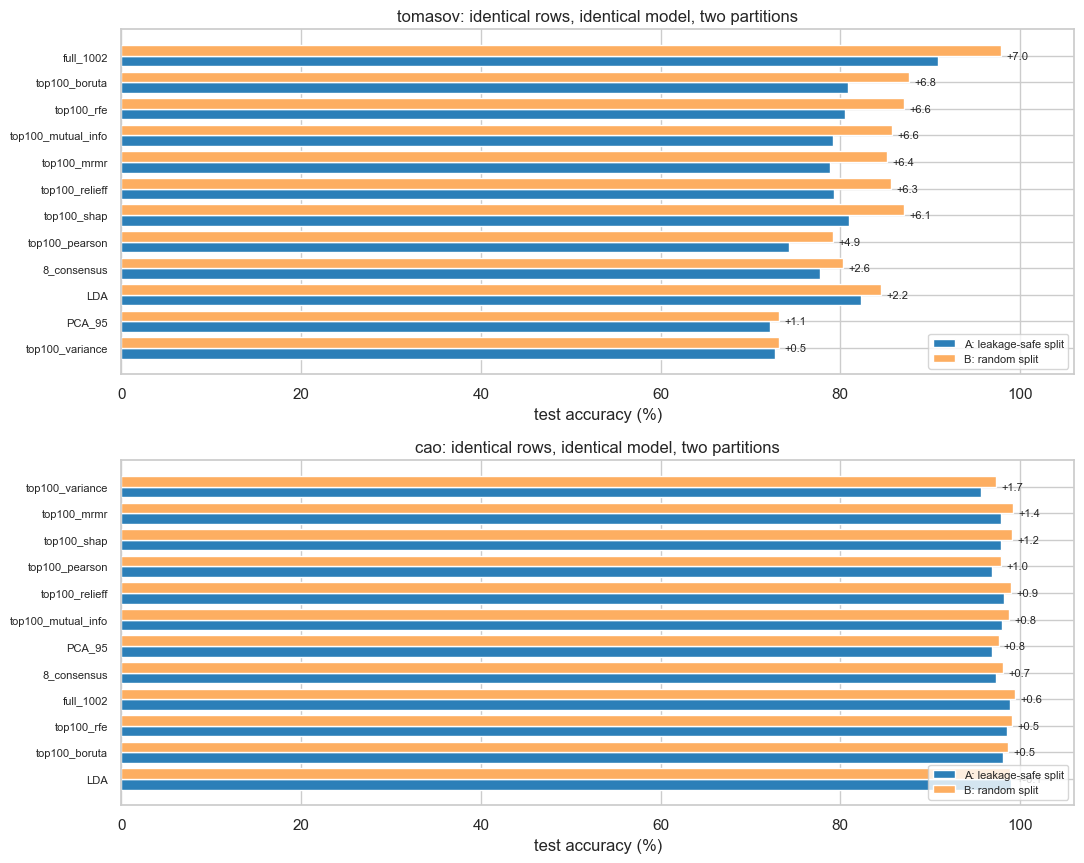

In [8]:
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(11, 4.4 * len(DATASETS)),
                         squeeze=False)
for ax, ds in zip(axes[:, 0], DATASETS):
    sub = infl[infl.dataset == ds].sort_values("acc_inflation_pp")
    ypos = np.arange(len(sub))
    ax.barh(ypos - 0.2, sub["acc_A_blocked"], height=0.4,
            color="#2c7fb8", label="A: leakage-safe split")
    ax.barh(ypos + 0.2, sub["acc_B_random"], height=0.4,
            color="#fdae61", label="B: random split")
    for i, (a, b) in enumerate(zip(sub["acc_A_blocked"], sub["acc_B_random"])):
        ax.text(max(a, b) + 0.6, i, f"+{b-a:.1f}", va="center", fontsize=8)
    ax.set_yticks(ypos)
    ax.set_yticklabels(sub["config"], fontsize=8)
    ax.set_xlabel("test accuracy (%)")
    ax.set_xlim(0, 106)
    ax.set_title(f"{ds}: identical rows, identical model, two partitions")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
fig.savefig(out_dir / "protocol_inflation.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
# Does the selector itself get fooled?  Compare how much the eight selectors
# agree with each other between the two arms.  If leakage changes which features
# look important, that is a finding in its own right.
jac = []
for ds in DATASETS:
    a, b = SEL[(ds, "A")], SEL[(ds, "B")]
    for m in C.FS_METHODS:
        ca, cb = top_k_cols(a, m), top_k_cols(b, m)
        if ca is None or cb is None:
            continue
        sa, sb = set(ca.tolist()), set(cb.tolist())
        jac.append({"dataset": ds, "method": m,
                    "overlap": len(sa & sb),
                    "jaccard": round(len(sa & sb) / len(sa | sb), 3)})
    cons_a = set(np.flatnonzero(FS.consensus_mask(a)).tolist())
    cons_b = set(np.flatnonzero(FS.consensus_mask(b)).tolist())
    if cons_a or cons_b:
        jac.append({"dataset": ds, "method": "8_consensus",
                    "overlap": len(cons_a & cons_b),
                    "jaccard": round(len(cons_a & cons_b) /
                                     max(len(cons_a | cons_b), 1), 3)})
jac = pd.DataFrame(jac)
display(jac)
jac.to_csv(out_dir / "selector_stability_across_arms.csv", index=False)
print("Jaccard near 1 means the selector picks the same features whichever")
print("protocol it is fitted under.  Low values mean leakage changes what")
print("looks important, not just how well it scores.")

,dataset,method,overlap,jaccard
0,tomasov,variance,99,0.980
1,tomasov,pearson,97,0.942
2,tomasov,mutual_info,68,0.515
3,tomasov,relieff,82,0.695
4,tomasov,mrmr,89,0.802
5,tomasov,rfe,44,0.282
6,tomasov,boruta,89,0.802
7,tomasov,shap,72,0.562
8,tomasov,8_consensus,33,0.569
9,cao,variance,99,0.980


Jaccard near 1 means the selector picks the same features whichever
protocol it is fitted under.  Low values mean leakage changes what
looks important, not just how well it scores.


## 6. What this licenses the paper to say

`protocol_inflation.csv` gives, for every configuration the manuscript reports, the
number of accuracy points attributable to the evaluation protocol alone. Three uses:

1. **Every headline table gains a protocol-sensitivity column.** That converts the
   paper's central claim from an argument into a measurement, and it is the direct
   answer to R2C3 generalised beyond the CNN.
2. **Literature numbers become comparable.** Any published result on these datasets
   obtained under a random split can be discounted by the inflation measured for a
   comparable configuration, which is what makes the head-to-head in notebook 16
   interpretable.
3. **`selector_stability_across_arms.csv` is a separate finding.** If the eight
   selectors choose substantially different features under the two protocols, then
   leakage corrupts feature-importance conclusions and not only accuracy - and every
   published DAS feature-ranking study that used a random split inherits that
   problem.